In [1]:
!unzip -q -o sample_data/archive -d mnist
!ls mnist

t10k-images-idx3-ubyte
t10k-images.idx3-ubyte
t10k-labels-idx1-ubyte
t10k-labels.idx1-ubyte
train-images-idx3-ubyte
train-images.idx3-ubyte
train-labels-idx1-ubyte
train-labels.idx1-ubyte


Читаем выборки - обучающую и тестовую + делаем строку(из 0-255), а затем таблицу 784x60000 для дальнейшей работы

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def read_images(path):
    with open(path, 'rb') as f:
        data = f.read()
    return np.frombuffer(data, dtype=np.uint8, offset=16).reshape(-1, 784)

def read_labels(path):
    with open(path, 'rb') as f:
        data = f.read()
    return np.frombuffer(data, dtype=np.uint8, offset=8)

X_train = read_images('mnist/train-images.idx3-ubyte')
y_train = read_labels('mnist/train-labels.idx1-ubyte')
X_test = read_images('mnist/t10k-images.idx3-ubyte')
y_test = read_labels('mnist/t10k-labels.idx1-ubyte')

Отмечаем как прочитались файлы

In [3]:
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)
print(X_train.dtype, X_train.min(), X_train.max())
print(np.bincount(y_train))
print(np.bincount(y_test))

(60000, 784) (60000,) (10000, 784) (10000,)
uint8 0 255
[5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]
[ 980 1135 1032 1010  982  892  958 1028  974 1009]


Смотрим как выглядит картинка и проверяем соответствие


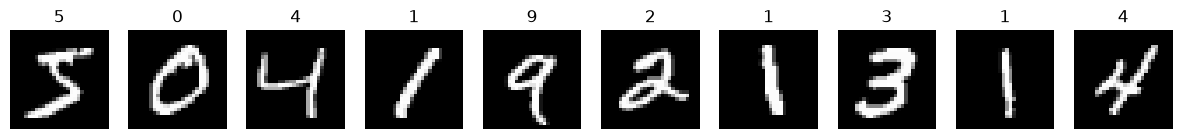

In [4]:
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for i, ax in enumerate(axes):
    ax.imshow(X_train[i].reshape(28, 28), cmap='gray')
    ax.set_title(y_train[i])
    ax.axis('off')
plt.show()

Приведём числа к диапазону 0-1, чтоы избежать накопления крупных чисел при проходах, а также сделаем единичную матрицу 10x10 для получения one-hot вектора

In [5]:
import time

Xtr = X_train.astype(np.float32) / 255.0
Xte = X_test.astype(np.float32) / 255.0
Ytr = np.eye(10, dtype=np.float32)[y_train]

## Теоретическая часть: прямой проход и функция ошибки

Обозначения: $B$ — размер пакета, $s=300$ — число скрытых нейронов, $X\in\mathbb{R}^{B\times 784}$ — пиксели пакета (после деления на 255), $Y\in\mathbb{R}^{B\times 10}$ — метки в виде one-hot.
Параметры сети: $W_1\in\mathbb{R}^{784\times s}$, $b_1\in\mathbb{R}^{s}$, $W_2\in\mathbb{R}^{s\times 10}$, $b_2\in\mathbb{R}^{10}$.

Прямой проход (на скрытом слое активация ReLU, на выходном softmax, у входного слоя активации нет):

$$Z_1 = XW_1 + b_1,\qquad A_1 = \max(0, Z_1),\qquad Z_2 = A_1W_2 + b_2,\qquad P_{ik} = \frac{e^{Z_{2,ik}}}{\sum_{j=1}^{10} e^{Z_{2,ij}}}.$$

Функция ошибки — кросс-энтропия, усреднённая по пакету:

$$L = -\frac{1}{B}\sum_{i=1}^{B}\sum_{k=1}^{10} Y_{ik}\ln P_{ik}.$$

В каждой строке $Y$ единица стоит только на месте верного класса $t_i$, поэтому $L = -\frac{1}{B}\sum_{i}\ln P_{i,t_i}$.

## Теоретическая часть: вывод формул обратного распространения

Градиенты считаем от выхода к входу по цепному правилу.

**1. Градиент по выходам последнего слоя $Z_2$.** Для одной картинки с верным классом $t$ и $S=\sum_j e^{z_j}$ имеем $\ln p_t = z_t - \ln S$, поэтому $L = -z_t + \ln S$. Тогда

$$\frac{\partial L}{\partial z_k} = -\frac{\partial z_t}{\partial z_k} + \frac{1}{S}\frac{\partial S}{\partial z_k} = -y_k + \frac{e^{z_k}}{S} = p_k - y_k,$$

где $\partial z_t/\partial z_k$ равно 1 при $k=t$ и 0 иначе, то есть равно $y_k$. С учётом усреднения по пакету:

$$dZ_2 = \frac{P - Y}{B}.$$

**2. Градиенты по параметрам второго слоя.** Так как $Z_{2,ik} = \sum_j A_{1,ij}W_{2,jk} + b_{2,k}$, то $\partial Z_{2,ik}/\partial W_{2,jk} = A_{1,ij}$ и $\partial Z_{2,ik}/\partial b_{2,k} = 1$. Параметры общие для всех картинок пакета, поэтому вклады суммируются по номеру картинки $i$:

$$dW_2 = A_1^{T}\,dZ_2,\qquad db_2 = \sum_{i} dZ_{2,i\cdot}.$$

**3. Градиент по выходу скрытого слоя.** Значение $A_{1,im}$ входит во все 10 выходов картинки $i$ с коэффициентами $W_{2,mk}$, поэтому

$$dA_1 = dZ_2\,W_2^{T}.$$

**4. Через ReLU.** Производная $\max(0,z)$ равна 1 при $z>0$ и 0 при $z\le 0$, поэтому

$$dZ_1 = dA_1 \odot \mathbb{1}[Z_1 > 0].$$

**5. Градиенты по параметрам первого слоя.** Аналогично пункту 2 (вместо $A_1$ на входе стоит $X$):

$$dW_1 = X^{T}\,dZ_1,\qquad db_1 = \sum_{i} dZ_{1,i\cdot}.$$

**6. Коррекция весов (стохастический градиентный спуск по пакетам).** Для каждого из параметров $W_1, b_1, W_2, b_2$:

$$W \leftarrow W - \eta\,dW,$$

где $\eta$ — скорость обучения. Один шаг делается на каждый пакет, эпоха — полный проход по обучающей выборке с перемешиванием.

Инициаизируем случайные веса и нулевые смещения, учитывая влияние количества входов на "раскачивание"суммы, а также обрезку примерно половины значений функцией активации ReLU. Задаём нормальное распределение, и путём домножения на корень, приводим к необходимому разбросу для дисперсии. Также задаём функцию прямого прохода и функции активации, сохраняя при этом устойчивость softmax.

In [6]:
def init_params(n_in, n_hid, n_out, seed=0):
    rng = np.random.default_rng(seed)
    W1 = (rng.standard_normal((n_in, n_hid)) * np.sqrt(2.0 / n_in)).astype(np.float32)
    b1 = np.zeros(n_hid, dtype=np.float32)
    W2 = (rng.standard_normal((n_hid, n_out)) * np.sqrt(2.0 / n_hid)).astype(np.float32)
    b2 = np.zeros(n_out, dtype=np.float32)
    return W1, b1, W2, b2

def softmax(Z):
    E = np.exp(Z - Z.max(axis=1, keepdims=True))
    return E / E.sum(axis=1, keepdims=True)

def forward(X, W1, b1, W2, b2):
    Z1 = X @ W1 + b1
    A1 = np.maximum(0, Z1)
    Z2 = A1 @ W2 + b2
    P = softmax(Z2)
    return Z1, A1, P

def loss(P, Y):
    return -np.mean(np.sum(Y * np.log(P + 1e-12), axis=1))

Задаём функцию обратного прохода


In [7]:
def backward(X, Y, Z1, A1, P, W2):
    B = X.shape[0]
    dZ2 = (P - Y) / B
    dW2 = A1.T @ dZ2
    db2 = dZ2.sum(axis=0)
    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * (Z1 > 0)
    dW1 = X.T @ dZ1
    db1 = dZ1.sum(axis=0)
    return dW1, db1, dW2, db2

def error_rate(X, y, params):
    _, _, P = forward(X, *params)
    return np.mean(np.argmax(P, axis=1) != y)

Проверка градиента. Изменяем веса, сравнивая наклон ошибки с градиентом. Считаем произвдную в лоб, по определению, при малых сдвигах веса, используем "Центральную разность", если обратный проход верен, число совпадёт с g[pos]. При этом оптимизировали: Идём по парам - параметр и его градиент, проверяя для каждого случайные 5 элементов(т.к. у W1 их 23520)

In [8]:
def grad_check(n_checks=5, eps=1e-5):
    params = [p.astype(np.float64) for p in init_params(784, 30, 10, seed=1)]
    X, Y = Xtr[:16].astype(np.float64), Ytr[:16].astype(np.float64)
    Z1, A1, P = forward(X, *params)
    grads = backward(X, Y, Z1, A1, P, params[2])
    rng = np.random.default_rng(0)
    worst = 0.0
    for p, g in zip(params, grads):
        for _ in range(n_checks):
            pos = tuple(rng.integers(0, s) for s in p.shape)
            old = p[pos]
            p[pos] = old + eps; lp = loss(forward(X, *params)[2], Y)
            p[pos] = old - eps; lm = loss(forward(X, *params)[2], Y)
            p[pos] = old
            worst = max(worst, abs((lp - lm) / (2 * eps) - g[pos]))
    return worst

print("максимальная разница:", grad_check())

максимальная разница: 3.19477638788257e-11


Обучение

In [9]:
def train(lr=0.1, batch=64, epochs=20, hidden=300, seed=0):
    params = init_params(784, hidden, 10, seed)
    W1, b1, W2, b2 = params
    rng = np.random.default_rng(seed)
    n = Xtr.shape[0]
    for ep in range(epochs):
        t0 = time.time()
        idx = rng.permutation(n)
        for s in range(0, n, batch):
            ib = idx[s:s + batch]
            X, Y = Xtr[ib], Ytr[ib]
            Z1, A1, P = forward(X, W1, b1, W2, b2)
            dW1, db1, dW2, db2 = backward(X, Y, Z1, A1, P, W2)
            W1 -= lr * dW1; b1 -= lr * db1
            W2 -= lr * dW2; b2 -= lr * db2
        print(f"эпоха {ep+1:2d}: ошибка на обучении {error_rate(Xtr, y_train, params):.4f}, время {time.time()-t0:.1f} c")
    return params

params = train()
print("ошибка на тесте:", error_rate(Xte, y_test, params))
err = error_rate(Xte, y_test, params)
print(f"ошибка классификации на тесте: {err:.2%}")
print(f"точность на тесте: {1 - err:.2%}")

эпоха  1: ошибка на обучении 0.0594, время 1.2 c


эпоха  2: ошибка на обучении 0.0452, время 1.0 c


эпоха  3: ошибка на обучении 0.0305, время 1.0 c


эпоха  4: ошибка на обучении 0.0259, время 1.0 c


эпоха  5: ошибка на обучении 0.0217, время 1.0 c


эпоха  6: ошибка на обучении 0.0184, время 1.1 c


... (10 outputs left out)

эпоха 17: ошибка на обучении 0.0046, время 1.0 c


эпоха 18: ошибка на обучении 0.0060, время 1.2 c


эпоха 19: ошибка на обучении 0.0023, время 1.0 c


эпоха 20: ошибка на обучении 0.0020, время 0.9 c
ошибка на тесте: 0.0193
ошибка классификации на тесте: 1.93%
точность на тесте: 98.07%
